# 08 · Prediction intervals (not just point forecasts)
We train LightGBM **quantile** models (5%, 10%, 25%, 50%, 75%, 90%, 95%), fix quantile crossing, then apply
**conformalized quantile regression (CQR)** using the validation window so that the 80% / 90% intervals
actually *cover* ~80% / 90% of outcomes. The quantiles also feed the inventory optimiser (notebook 09).

In [1]:
import sys; sys.path.insert(0, "..")
import warnings, logging; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from src.config import *
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3})

import lightgbm as lgb
from src.features import time_split
from src.metrics import interval_coverage, pinball_loss
feat = pd.read_parquet(PROC_DIR / "features.parquet")
FEATS = json.load(open(PROC_DIR / "feature_list.json"))
CATS = ["item_id", "dept_id", "cat_id", "store_id", "state_id", "event_type_1"]
for c in CATS: feat[c] = feat[c].astype("category")
tr, va, te = time_split(feat)

In [2]:
qcols = [f"q{int(q*100):02d}" for q in QUANTILES]
pred_va, pred_te = va[["id", "date", "sales"]].copy(), te[["id", "date", "sales"]].copy()
for q, col in zip(QUANTILES, qcols):
    p = dict(objective="quantile", alpha=q, learning_rate=0.08, num_leaves=63, min_data_in_leaf=50,
             feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, verbose=-1, seed=SEED)
    dtr = lgb.Dataset(tr[FEATS], tr.sales, categorical_feature=CATS)
    dva = lgb.Dataset(va[FEATS], va.sales, reference=dtr)
    m = lgb.train(p, dtr, num_boost_round=600, valid_sets=[dva], callbacks=[lgb.early_stopping(40, verbose=False)])
    pred_va[col] = m.predict(va[FEATS], num_iteration=m.best_iteration)
    pred_te[col] = m.predict(te[FEATS], num_iteration=m.best_iteration)
    print(f"{col}: best iter {m.best_iteration}, test pinball {pinball_loss(te.sales, pred_te[col], q):.4f}")
for d in (pred_va, pred_te):                            # fix crossing + non-negativity
    d[qcols] = np.clip(np.sort(d[qcols].values, axis=1), 0, None)

q05: best iter 201, test pinball 0.0885


q10: best iter 186, test pinball 0.1724


q25: best iter 428, test pinball 0.3853


q50: best iter 328, test pinball 0.5903


q75: best iter 167, test pinball 0.5364


q90: best iter 151, test pinball 0.3350


q95: best iter 82, test pinball 0.2099


## Conformal calibration (CQR) on the validation window
Score = how far the true value falls outside the raw interval; the (1-α) quantile of those scores widens
(or narrows) the interval on the test window.

In [3]:
def cqr(lo_col, hi_col, alpha):
    y = pred_va.sales.values
    score = np.maximum(pred_va[lo_col].values - y, y - pred_va[hi_col].values)
    n = len(score); level = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
    qhat = np.quantile(score, level)
    return np.clip(pred_te[lo_col] - qhat, 0, None), pred_te[hi_col] + qhat, qhat

pred_te["lo80_cal"], pred_te["hi80_cal"], q80 = cqr("q10", "q90", 0.20)
pred_te["lo90_cal"], pred_te["hi90_cal"], q90 = cqr("q05", "q95", 0.10)
y = pred_te.sales
rows = []
for name, (lo, hi), target in [("80% raw", ("q10", "q90"), .8), ("80% calibrated", ("lo80_cal", "hi80_cal"), .8),
                               ("90% raw", ("q05", "q95"), .9), ("90% calibrated", ("lo90_cal", "hi90_cal"), .9)]:
    rows.append(dict(interval=name, target=target, coverage=interval_coverage(y, pred_te[lo], pred_te[hi]),
                     avg_width=float((pred_te[hi] - pred_te[lo]).mean())))
cov = pd.DataFrame(rows).round(4); cov.to_csv(OUT_DIR / "metrics_intervals.csv", index=False); cov

,interval,target,coverage,avg_width
0,80% raw,0.8,0.8564,3.6641
1,80% calibrated,0.8,0.8564,3.6641
2,90% raw,0.9,0.9387,4.5969
3,90% calibrated,0.9,0.9387,4.5969


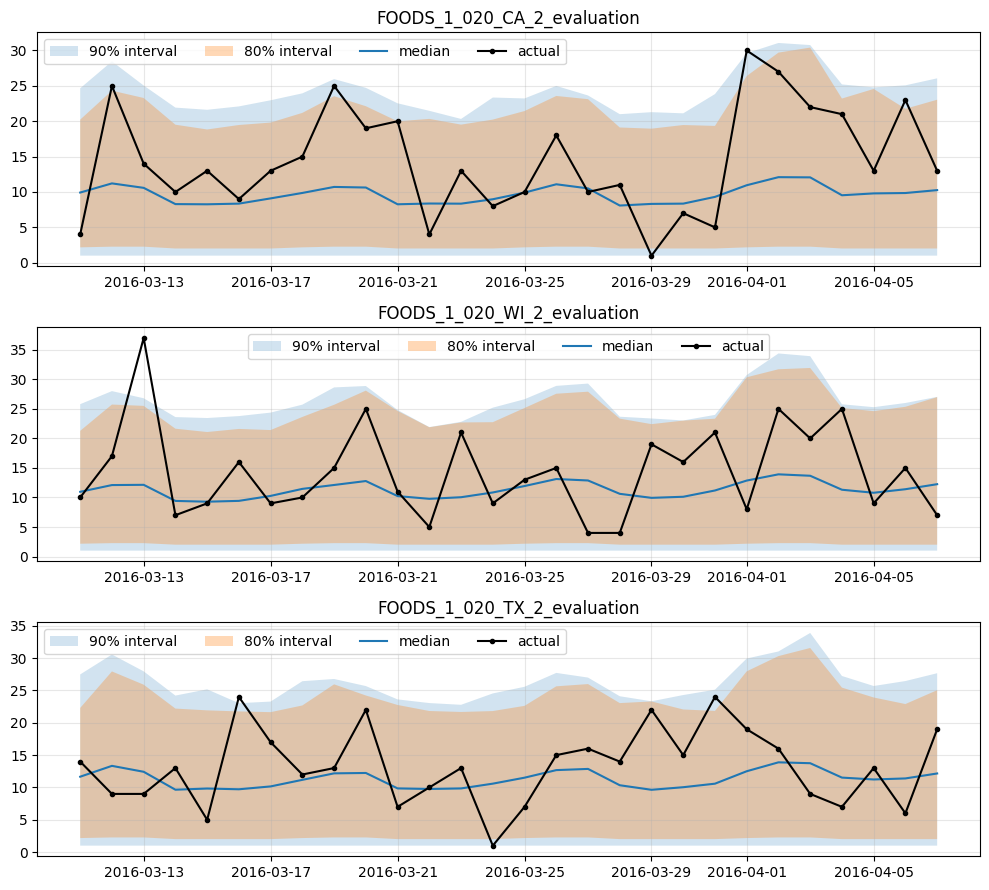

In [4]:
pred_te.to_parquet(OUT_DIR / "forecast_quantiles.parquet")
fig, axes = plt.subplots(3, 1, figsize=(10, 9))
for ax, sid in zip(axes, pred_te.groupby("id")["sales"].sum().nlargest(3).index):
    t = pred_te[pred_te.id == sid].sort_values("date")
    ax.fill_between(t.date, t.lo90_cal, t.hi90_cal, alpha=.2, label="90% interval")
    ax.fill_between(t.date, t.lo80_cal, t.hi80_cal, alpha=.3, label="80% interval")
    ax.plot(t.date, t.q50, label="median"); ax.plot(t.date, t.sales, "k.-", label="actual"); ax.set_title(sid); ax.legend(ncol=4)
plt.tight_layout(); plt.savefig(FIG_DIR / "08_intervals.png", dpi=120); plt.show()

**Note for the presentation:** report *coverage* next to the plots. Coverage near the target (e.g. 80%) is what
makes the intervals trustworthy for the stock decisions in notebook 09.